# Proyek Analisis Sentimen: Ulasan Aplikasi WeTV
- **Nama:** Imam Riyadi
- **Email:** imaammriyadi@gmail.com
- **ID Dicoding:** mamyadi

## Deskripsi Proyek
Notebook ini memuat alur lengkap analisis sentimen ulasan aplikasi streaming WeTV (`com.tencent.qqlivei18n`) yang dikumpulkan langsung dari Google Play Store. Alur analisis mencakup data loading, inspeksi tipe data, seleksi fitur esensial, pembersihan missing value & duplikasi, text preprocessing, pelabelan sentimen objektif berbasis leksikon (3 kelas: Positif, Netral, Negatif), ekstraksi fitur komparatif, pelatihan 3 skema model (ML & Deep Learning BiLSTM), hingga pengujian inferensi data baru.

# 1. Loading & Inspeksi Dataset
Tahap ini memuat data mentah hasil penarikan ulasan (`wetv-reviews-raw.csv`), melakukan inspeksi awal struktur DataFrame (tipe data, dimensi, dan missing values), menyeleksi fitur utama (`content` dan `score`), serta memvalidasi kesesuaian tipe data.

In [44]:
import pandas as pd
import numpy as np

In [45]:
# Load dataset hasil scraping
raw_csv_path = "wetv-reviews-raw.csv"
df_raw = pd.read_csv(raw_csv_path)

print(f"Dataset berhasil dimuat!")
print(f"Dimensi data mentah : {df_raw.shape[0]} baris, {df_raw.shape[1]} kolom")
print("-" * 50)
df_raw.head()

Dataset berhasil dimuat!
Dimensi data mentah : 12000 baris, 11 kolom
--------------------------------------------------


,reviewId,userName,userImage,content,score,thumbsUpCount,reviewCreatedVersion,at,replyContent,repliedAt,appVersion
0,21c5057c-bace-4f6a-a7a5-df43a5dd09ef,Mas Arif Syawal,https://play-lh.googleusercontent.com/a/ACg8oc...,Sangat bagus dan membantu.,5,0,NaN,2026-10-04 11:35:07,"Halo, Kak! Terima kasih untuk rating dan revie...",2026-10-04 14:01:42,NaN
1,7e7c2aa1-93f3-42ff-96d1-a69e955d3ab5,Lucky Rada,https://play-lh.googleusercontent.com/a/ACg8oc...,"sudah beli kok masih proses sampai sekarang, g...",1,0,5.39.5.18470,2026-10-04 08:36:11,"Hai, Kak. Mohon maaf ya. Pastikan Kakak sudah ...",2026-10-03 00:31:49,5.39.5.18470
2,3617801f-f64d-45ba-99a1-d4600c6aca4d,Asep Sunandar,https://play-lh.googleusercontent.com/a-/ALV-U...,Sudah bayar buat langganan VIP tapi masih bany...,1,0,NaN,2026-10-04 00:48:08,"Hi Kak, Saat ini bisa coba ke menu setting > I...",2026-10-04 00:33:59,NaN
3,c7f4c6e9-dce8-4b07-b21d-7a68747ec1d0,Ano Inuyasha,https://play-lh.googleusercontent.com/a-/ALV-U...,loncat terus ke app iklan.. 😤,1,1,3.2.4.58371,2026-10-03 22:15:36,"Hi Kak, Saat ini bisa coba ke menu setting > I...",2026-10-04 00:32:44,3.2.4.58371
4,6847770d-3852-412b-9bf9-e07000ee4830,Achmad Taufiq T (‫تَوْفِيقِي‬‎),https://play-lh.googleusercontent.com/a-/ALV-U...,sudah langganan vip tapi masih muncul iklan sa...,1,0,5.39.5.18470,2026-10-03 17:21:06,"Hai, kak! Mohon maaf atas kendalanya. Untuk pe...",2026-10-03 18:33:33,5.39.5.18470


In [46]:
# Menampilkan ringkasan tipe data dan keberadaan null
print("--- Ringkasan Struktur Data Mentah ---")
df_raw.info()

print("\n--- Jumlah Nilai Kosong (Missing Values) Per Kolom ---")
print(df_raw.isnull().sum())

--- Ringkasan Struktur Data Mentah ---
<class 'pandas.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   reviewId              12000 non-null  str  
 1   userName              12000 non-null  str  
 2   userImage             12000 non-null  str  
 3   content               12000 non-null  str  
 4   score                 12000 non-null  int64
 5   thumbsUpCount         12000 non-null  int64
 6   reviewCreatedVersion  7695 non-null   str  
 7   at                    12000 non-null  str  
 8   replyContent          11984 non-null  str  
 9   repliedAt             11984 non-null  str  
 10  appVersion            7695 non-null   str  
dtypes: int64(2), str(9)
memory usage: 1.0 MB

--- Jumlah Nilai Kosong (Missing Values) Per Kolom ---
reviewId                   0
userName                   0
userImage                  0
content                    0
score   

In [47]:
# Mengganti kolom tanggal ke tipe datetime
df_raw['at'] = pd.to_datetime(df_raw['at'], errors='coerce')
df_raw['repliedAt'] = pd.to_datetime(df_raw['repliedAt'], errors='coerce')

# Mengisi nilai kosong (Missing Values) tanpa menghapus baris ulasan
# Mengisi versi aplikasi yang tidak terdeteksi
df_raw['appVersion'] = df_raw['appVersion'].fillna('Unknown')
df_raw['reviewCreatedVersion'] = df_raw['reviewCreatedVersion'].fillna('Unknown')

# Mengisi balasan developer yang tidak ada
df_raw['replyContent'] = df_raw['replyContent'].fillna('No Reply')

# Menghapus duplikasi ulasan pada teks 'content'
initial_count = len(df_raw)
df_raw.drop_duplicates(subset=['content'], inplace=True)
duplicate_removed = initial_count - len(df_raw)

# Memastikan teks ulasan bertipe string
df_raw['content'] = df_raw['content'].astype(str)

# Mereset index setelah drop duplicates
df_raw.reset_index(drop=True, inplace=True)

In [48]:
# Menampilkan ringkasan hasil
print("--- Hasil Penyesuaian Tipe Data & Pembersihan Data ---")
print(f"Data awal                : {initial_count} baris")
print(f"Duplikat terhapus        : {duplicate_removed} baris")
print(f"Total data bersih siap pakai: {len(df_raw)} baris")
print("-" * 55)
print("\n--- Verifikasi Missing Values ---")
print(df_raw.isnull().sum())
print("\n--- Struktur Tipe Data Baru ---")
df_raw.info()

--- Hasil Penyesuaian Tipe Data & Pembersihan Data ---
Data awal                : 12000 baris
Duplikat terhapus        : 999 baris
Total data bersih siap pakai: 11001 baris
-------------------------------------------------------

--- Verifikasi Missing Values ---
reviewId                 0
userName                 0
userImage                0
content                  0
score                    0
thumbsUpCount            0
reviewCreatedVersion     0
at                       0
replyContent             0
repliedAt               16
appVersion               0
dtype: int64

--- Struktur Tipe Data Baru ---
<class 'pandas.DataFrame'>
RangeIndex: 11001 entries, 0 to 11000
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   reviewId              11001 non-null  str           
 1   userName              11001 non-null  str           
 2   userImage             11001 non-null  str           
 3   

> **Catatan Pembersihan Data:**  
> Sebanyak 16 baris pada kolom `repliedAt` berstatus `NaT` (*Not a Time*). Hal ini konsisten dengan kolom `replyContent` yang bernilai `'No Reply'` (ulasan tidak memperoleh balasan dari pengembang). Nilai `NaT` dipertahankan apa adanya demi menjaga integritas data historis dan tidak memengaruhi proses pemodelan karena atribut pelatihan berfokus pada teks ulasan (`content`).

# 2. Text Preprocessing
Tahap pembersihan dan standardisasi teks ulasan WeTV
1. **Cleaning**: Menghapus mention, hashtag, URL, angka, karakter khusus, dan tanda baca.
2. **Case Folding**: Mengubah seluruh huruf menjadi huruf kecil (*lowercase*).
3. **Slangwords Normalization**: Memetakan kata-kata informal dan singkatan khas ulasan WeTV ke bentuk baku.
4. **Tokenizing**: Memecah kalimat menjadi token kata.
5. **Selective Stopword Filtering**: Menghapus kata umum tanpa membuang kata negasi kunci (*tidak*, *bukan*, *jangan*, *belum*, *kurang*).

In [49]:
import re
import string
import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords

# Download tokenizer & corpus NLTK
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

[nltk_data] Downloading package punkt to /home/imamriyadi/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     /home/imamriyadi/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     /home/imamriyadi/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [50]:
# Kamus slangwords
slangwords = {
    'udah': 'sudah', 'aja': 'saja', 'yg': 'yang', 'ya': 'iya', 'malah': 'bahkan',
    'kalo': 'kalau', 'pake': 'pakai', 'bgt': 'banget', 'tp': 'tapi', 'gimana': 'bagaimana',
    'dah': 'deh', 'tpi': 'tapi', 'klo': 'kalau', 'mulu': 'melulu', 'gw': 'saya',
    'sampe': 'sampai', 'ok': 'ok', 'ni': 'ini', 'd': 'di', 'tau': 'tahu',
    'karna': 'karena', 'mending': 'lebih baik', 'lg': 'lagi', 'gua': 'saya', 'nggak': 'tidak',
    'nih': 'ini', 'tdk': 'tidak', 'liat': 'lihat', 'knp': 'kenapa', 'lemot': 'lambat',
    'ngga': 'tidak', 'sy': 'saya', 'jg': 'juga', 'lgi': 'lagi', 'jd': 'jadi',
    'jdi': 'jadi', 'bener': 'benar', 'apaan': 'apa', 'trs': 'terus', 'bnyk': 'banyak',
    'udh': 'sudah', 'bgtt': 'banget', 'blm': 'belum', 'jgn': 'jangan', 'bs': 'bisa',
    'kl': 'kalau', 'krn': 'karena', 'utk': 'untuk', 'pas': 'saat', 'capek': 'lelah',
    'dr': 'dari', 'bisaa': 'bisa', 'byk': 'banyak', 'gitu': 'begitu', 'bangett': 'banget',
    'baguss': 'bagus', 'bgtu': 'begitu', 'dpt': 'dapat', 'sdh': 'sudah', 'lgsg': 'langsung',
    'gt': 'begitu', 'makin': 'semakin', 'ntn': 'menonton', 'nonton': 'menonton', 'nntn': 'menonton',
    'makasih': 'terima kasih', 'nyesel': 'menyesal', 'parah': 'buruk', 'rekomen': 'rekomendasi',
    'rusak': 'rusak', 'tauk': 'tahu', 'gak': 'tidak', 'ga': 'tidak', 'apk': 'aplikasi', 'app': 'aplikasi'
}

print(f"Kamus slang terdaftar: {len(slangwords)} kata unik ulasan WeTV.")

Kamus slang terdaftar: 75 kata unik ulasan WeTV.


In [51]:
# Pembersihan teks
def clean_text(text):
    text = re.sub(r'@[A-Za-z0-9_]+', '', text)        # Hapus mention
    text = re.sub(r'#\w+', '', text)                  # Hapus hashtag
    text = re.sub(r'RT[\s]+', '', text)               # Hapus RT
    text = re.sub(r'https?://\S+|www\.\S+', '', text) # Hapus URL
    text = re.sub(r'[0-9]+', '', text)                # Hapus angka
    text = re.sub(r'[^\w\s]', ' ', text)              # Hapus tanda baca/simbol
    text = text.replace('\n', ' ')                    # Ganti newline ke spasi
    text = re.sub(r'\s+', ' ', text).strip()          # Normalisasi spasi ganda
    return text

# Case folding
def case_fold(text):
    return text.lower()

# Normalisasi kata slang
def normalize_slang(text):
    words = text.split()
    return ' '.join([slangwords.get(w, w) for w in words])

# Tokenisasi
def tokenize(text):
    return word_tokenize(text)

# Stopword Filtering Selektif (Menjaga kata negasi)
negation_words = {'tidak', 'bukan', 'jangan', 'belum', 'kurang', 'tanpa'}
base_stopwords = set(stopwords.words('indonesian')) | set(stopwords.words('english'))
custom_stopwords = (base_stopwords - negation_words) | {'iya', 'yaa', 'nya', 'sih', 'ku', 'deh', 'loh', 'kah'}

def filter_stopwords(tokens):
    return [word for word in tokens if word not in custom_stopwords and len(word) > 1]

# Menggabungkan token kembali ke kalimat
def tokens_to_sentence(tokens):
    return ' '.join(tokens)

print("Seluruh fungsi preprocessing siap digunakan.")

Seluruh fungsi preprocessing siap digunakan.


In [52]:
print("Menjalankan pipeline preprocessing data...")

# Eksekusi berurutan sesuai tahapan preprocessing
df_raw['content_clean'] = df_raw['content'].apply(clean_text)
df_raw['content_casefold'] = df_raw['content_clean'].apply(case_fold)
df_raw['content_normalize'] = df_raw['content_casefold'].apply(normalize_slang)
df_raw['content_token'] = df_raw['content_normalize'].apply(tokenize)
df_raw['content_stopword'] = df_raw['content_token'].apply(filter_stopwords)
df_raw['content_processed'] = df_raw['content_stopword'].apply(tokens_to_sentence)

# Filter baris yang teksnya kosong setelah pembersihan
empty_mask = df_raw['content_processed'].str.strip() == ''
print(f"Ulasan kosong setelah dibersihkan : {empty_mask.sum()} baris")

df_clean = df_raw[~empty_mask].copy().reset_index(drop=True)
print(f"Total ulasan bersih siap diproses: {len(df_clean)} baris")

# Tampilkan preview perbandingan kolom bertahap
df_clean[['content', 'content_clean', 'content_casefold', 'content_normalize', 'content_token', 'content_stopword', 'content_processed']].head()

Menjalankan pipeline preprocessing data...
Ulasan kosong setelah dibersihkan : 87 baris
Total ulasan bersih siap diproses: 10914 baris


,content,content_clean,content_casefold,content_normalize,content_token,content_stopword,content_processed
0,Sangat bagus dan membantu.,Sangat bagus dan membantu,sangat bagus dan membantu,sangat bagus dan membantu,"[sangat, bagus, dan, membantu]","[bagus, membantu]",bagus membantu
1,"sudah beli kok masih proses sampai sekarang, g...",sudah beli kok masih proses sampai sekarang ga...,sudah beli kok masih proses sampai sekarang ga...,sudah beli kok masih proses sampai sekarang ti...,"[sudah, beli, kok, masih, proses, sampai, seka...","[beli, proses, tidak, aplikasi]",beli proses tidak aplikasi
2,Sudah bayar buat langganan VIP tapi masih bany...,Sudah bayar buat langganan VIP tapi masih bany...,sudah bayar buat langganan vip tapi masih bany...,sudah bayar buat langganan vip tapi masih bany...,"[sudah, bayar, buat, langganan, vip, tapi, mas...","[bayar, langganan, vip, iklan, muncul, iklan, ...",bayar langganan vip iklan muncul iklan pinjol ...
3,loncat terus ke app iklan.. 😤,loncat terus ke app iklan,loncat terus ke app iklan,loncat terus ke aplikasi iklan,"[loncat, terus, ke, aplikasi, iklan]","[loncat, aplikasi, iklan]",loncat aplikasi iklan
4,sudah langganan vip tapi masih muncul iklan sa...,sudah langganan vip tapi masih muncul iklan sa...,sudah langganan vip tapi masih muncul iklan sa...,sudah langganan vip tapi masih muncul iklan sa...,"[sudah, langganan, vip, tapi, masih, muncul, i...","[langganan, vip, muncul, iklan, pause, jujur, ...",langganan vip muncul iklan pause jujur mengang...


# 3. Pelabelan Sentimen Berbasis Leksikon (InSet Lexicon)
Pelabelan data dilakukan secara otomatis menggunakan kamus polaritas leksikon Bahasa Indonesia (InSet Lexicon) tanpa mengandalkan rating bintang Play Store. 

Skor polaritas dihitung dari akumulasi bobot kata positif dan negatif dalam setiap ulasan:
- **Positif**: Skor polaritas > 0
- **Netral**: Skor polaritas == 0
- **Negatif**: Skor polaritas < 0

In [53]:
import csv
import requests
from io import StringIO

In [54]:
# Inisialisasi kamus leksikon
lexicon_positive = {}
lexicon_negative = {}

# Load Leksikon Positif
url_pos = 'https://raw.githubusercontent.com/angelmetanosaa/dataset/main/lexicon_positive.csv'
response_pos = requests.get(url_pos)
if response_pos.status_code == 200:
    reader = csv.reader(StringIO(response_pos.text), delimiter=',')
    for row in reader:
        lexicon_positive[row[0]] = int(row[1])
    print(f"Leksikon positif berhasil dimuat: {len(lexicon_positive)} kata.")
else:
    print("Gagal load leksikon positif.")

# Load Leksikon Negatif
url_neg = 'https://raw.githubusercontent.com/angelmetanosaa/dataset/main/lexicon_negative.csv'
response_neg = requests.get(url_neg)
if response_neg.status_code == 200:
    reader = csv.reader(StringIO(response_neg.text), delimiter=',')
    for row in reader:
        lexicon_negative[row[0]] = int(row[1])
    print(f"Leksikon negatif berhasil dimuat: {len(lexicon_negative)} kata.")
else:
    print("Gagal load leksikon negatif.")

Leksikon positif berhasil dimuat: 3609 kata.
Leksikon negatif berhasil dimuat: 6607 kata.


In [55]:
def calculate_polarity(tokens):
    score = 0
    
    # Hitung bobot kata positif
    for word in tokens:
        if word in lexicon_positive:
            score += lexicon_positive[word]
            
    # Hitung bobot kata negatif
    for word in tokens:
        if word in lexicon_negative:
            score += lexicon_negative[word]
            
    # Penentuan label 3 kelas
    if score > 0:
        polarity = 'positif'
    elif score < 0:
        polarity = 'negatif'
    else:
        polarity = 'netral'
        
    return score, polarity

# Terapkan pelabelan ke kolom tokens
print("Menjalankan pelabelan sentimen pada seluruh data...")
results = df_clean['content_stopword'].apply(calculate_polarity)
results = list(zip(*results))

# Simpan skor dan label ke dalam DataFrame
df_clean['polarity_score'] = results[0]
df_clean['polarity'] = results[1]

# Tampilkan distribusi frekuensi kelas
print("\n--- Distribusi Sentimen Hasil Pelabelan ---")
print(df_clean['polarity'].value_counts())
print("\n--- Persentase Distribusi Kelas ---")
print(df_clean['polarity'].value_counts(normalize=True) * 100)

Menjalankan pelabelan sentimen pada seluruh data...

--- Distribusi Sentimen Hasil Pelabelan ---
polarity
negatif    7209
positif    2130
netral     1575
Name: count, dtype: int64

--- Persentase Distribusi Kelas ---
polarity
negatif    66.052776
positif    19.516218
netral     14.431006
Name: proportion, dtype: float64


In [56]:
# Memverifikasi total baris data yang telah berhasil diproses dan diberi label sentimen
print(f"Total baris data siap pakai: {len(df_clean)}")

# Menampilkan 5 sampel teratas untuk validasi kesesuaian teks olahan, skor leksikon, dan kelas polaritas
df_clean[['content', 'content_processed', 'polarity_score', 'polarity']].head()

Total baris data siap pakai: 10914


,content,content_processed,polarity_score,polarity
0,Sangat bagus dan membantu.,bagus membantu,-2,negatif
1,"sudah beli kok masih proses sampai sekarang, g...",beli proses tidak aplikasi,-9,negatif
2,Sudah bayar buat langganan VIP tapi masih bany...,bayar langganan vip iklan muncul iklan pinjol ...,-30,negatif
3,loncat terus ke app iklan.. 😤,loncat aplikasi iklan,-4,negatif
4,sudah langganan vip tapi masih muncul iklan sa...,langganan vip muncul iklan pause jujur mengang...,-5,negatif


# 4. Exploratory Data Analysis (EDA)
Tahap eksplorasi data bertujuan untuk memahami karakteristik dataset ulasan WeTV secara visual:
1. **Distribusi Kelas Sentimen**: Mengamati proporsi dan perbandingan jumlah ulasan berkategori Negatif, Positif, dan Netral menggunakan visualisasi *Bar Chart* dan *Donut/Pie Chart*.
2. **Distribusi Panjang Karakter/Kata**: Menganalisis sebaran panjang kata ulasan pengguna untuk menentukan batas panjang sekuens (*max sequence length*) yang optimal pada model Deep Learning.
3. **Word Cloud**: Mengidentifikasi kata kunci yang paling sering muncul pada sentimen positif dan sentimen negatif untuk memetakan kepuasan serta keluhan pengguna WeTV.

In [57]:
import matplotlib.pyplot as plt
import seaborn as sns

/tmp/ipykernel_3329/686512210.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


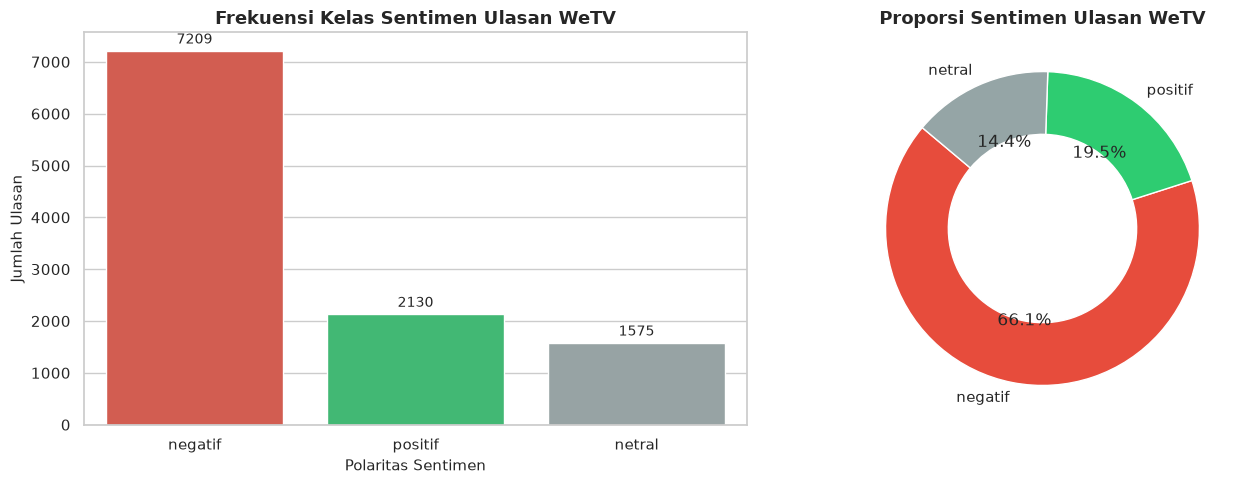

In [58]:
# Atur gaya visualisasi
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Bar Plot Distribusi Kelas
colors = ['#e74c3c', '#2ecc71', '#95a5a6']  # Merah (Negatif), Hijau (Positif), Abu-abu (Netral)
palette_dict = {'negatif': colors[0], 'positif': colors[1], 'netral': colors[2]}

sns.countplot(
    data=df_clean, 
    x='polarity', 
    order=['negatif', 'positif', 'netral'], 
    palette=palette_dict, 
    ax=axes[0]
)
axes[0].set_title('Frekuensi Kelas Sentimen Ulasan WeTV', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Polaritas Sentimen', fontsize=11)
axes[0].set_ylabel('Jumlah Ulasan', fontsize=11)

# Tambahkan label angka di atas setiap bar
for p in axes[0].patches:
    height = p.get_height()
    axes[0].annotate(f'{int(height)}',
                     (p.get_x() + p.get_width() / 2., height),
                     ha='center', va='bottom', fontsize=10, xytext=(0, 3),
                     textcoords='offset points')

# Donut / Pie Chart Proporsi
counts = df_clean['polarity'].value_counts()
labels = counts.index
axes[1].pie(
    counts, 
    labels=labels, 
    autopct='%1.1f%%', 
    startangle=140, 
    colors=[palette_dict[l] for l in labels],
    wedgeprops=dict(width=0.4, edgecolor='white')
)
axes[1].set_title('Proporsi Sentimen Ulasan WeTV', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()

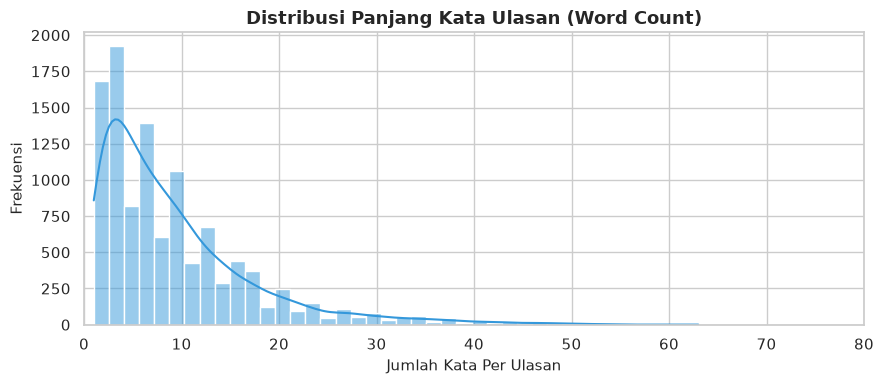

--- Ringkasan Statistik Panjang Kata ---
count    10914.000000
mean         9.295309
std          8.151678
min          1.000000
50%          7.000000
75%         12.000000
90%         20.000000
95%         26.000000
max         63.000000
Name: word_count, dtype: float64


In [59]:
# Menghitung jumlah kata per ulasan yang sudah diproses
df_clean['word_count'] = df_clean['content_processed'].apply(lambda x: len(x.split()))

plt.figure(figsize=(9, 4))
sns.histplot(df_clean['word_count'], bins=40, kde=True, color='#3498db')
plt.title('Distribusi Panjang Kata Ulasan (Word Count)', fontsize=13, fontweight='bold')
plt.xlabel('Jumlah Kata Per Ulasan', fontsize=11)
plt.ylabel('Frekuensi', fontsize=11)
plt.xlim(0, 80)  # Menyesuaikan batas umum ulasan pengguna
plt.tight_layout()
plt.show()

print("--- Ringkasan Statistik Panjang Kata ---")
print(df_clean['word_count'].describe(percentiles=[0.5, 0.75, 0.9, 0.95]))

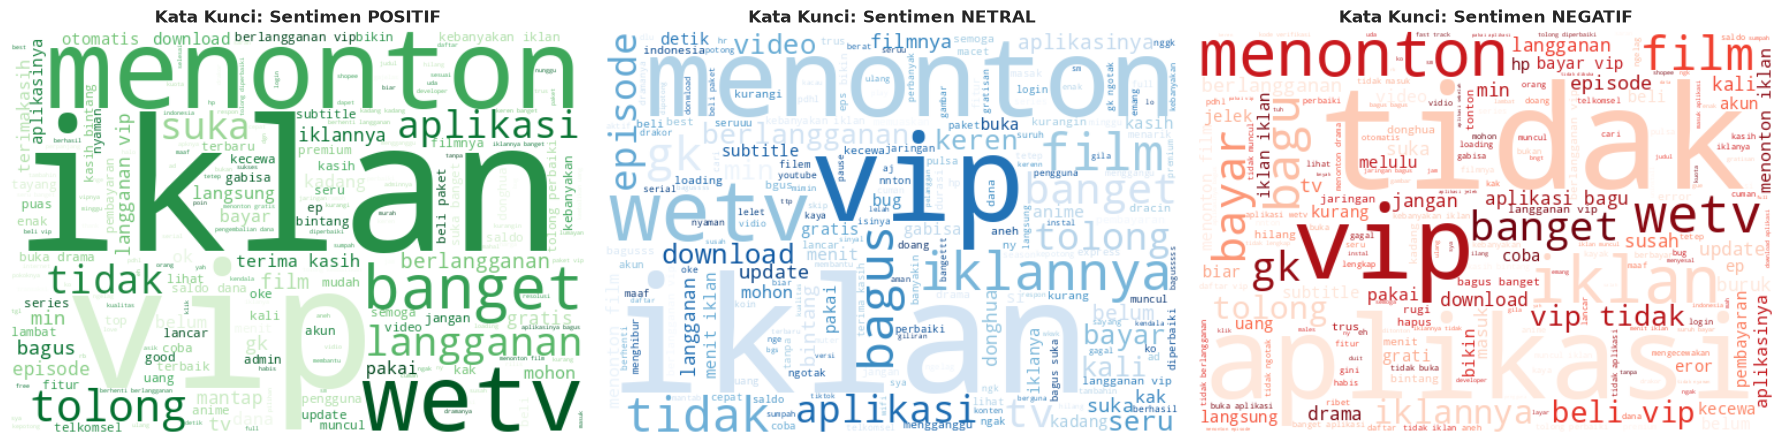

In [60]:
from wordcloud import WordCloud

# Kumpulan kata ulasan positif
pos_text = ' '.join(df_clean[df_clean['polarity'] == 'positif']['content_processed'])
wc_pos = WordCloud(width=500, height=350, background_color='white', colormap='Greens').generate(pos_text)

# Kumpulan kata ulasan netral
neu_text = ' '.join(df_clean[df_clean['polarity'] == 'netral']['content_processed'])
wc_neu = WordCloud(width=500, height=350, background_color='white', colormap='Blues').generate(neu_text)

# Kumpulan kata ulasan negatif
neg_text = ' '.join(df_clean[df_clean['polarity'] == 'negatif']['content_processed'])
wc_neg = WordCloud(width=500, height=350, background_color='white', colormap='Reds').generate(neg_text)

# Plot WordCloud 3 kelas berdampingan
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].imshow(wc_pos, interpolation='bilinear')
axes[0].set_title('Kata Kunci: Sentimen POSITIF', fontsize=12, fontweight='bold')
axes[0].axis('off')

axes[1].imshow(wc_neu, interpolation='bilinear')
axes[1].set_title('Kata Kunci: Sentimen NETRAL', fontsize=12, fontweight='bold')
axes[1].axis('off')

axes[2].imshow(wc_neg, interpolation='bilinear')
axes[2].set_title('Kata Kunci: Sentimen NEGATIF', fontsize=12, fontweight='bold')
axes[2].axis('off')

plt.tight_layout()
plt.show()

# 5. Pembagian Data & Ekstraksi Fitur (TF-IDF)
Pada tahap ini:
1. **Pemisahan Data**: Dataset ulasan dibagi dengan rasio **80:20** (80% data latih dan 20% data uji) menggunakan parameter `stratify=y` agar proporsi ketiga kelas sentimen (*negatif*, *positif*, *netral*) terjaga seimbang di kedua set.
2. **Ekstraksi Fitur TF-IDF**: Teks pada data latih ditransformasikan ke matriks bobot frekuensi kata (*Term Frequency-Inverse Document Frequency*). Objek TF-IDF di-*fit* hanya pada data latih karena untuk mencegah kebocoran data (*data leakage*).

In [61]:
from sklearn.model_selection import train_test_split

# Menentukan fitur input (X) dan target label (y)
X = df_clean['content_processed']
y = df_clean['polarity']

# Pembagian data 80% train dan 20% test dengan stratify
X_train, X_test, y_train, y_test = train_test_split(
    X, 
    y, 
    test_size=0.2, 
    random_state=42, 
    stratify=y
)

print("--- Hasil Pembagian Data (80:20) ---")
print(f"Jumlah Data Latih (Train) : {len(X_train)} baris")
print(f"Jumlah Data Uji (Test)   : {len(X_test)} baris")

print("\n--- Distribusi Kelas pada Data Latih (%) ---")
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\n--- Distribusi Kelas pada Data Uji (%) ---")
print((y_test.value_counts(normalize=True) * 100).round(2))

--- Hasil Pembagian Data (80:20) ---
Jumlah Data Latih (Train) : 8731 baris
Jumlah Data Uji (Test)   : 2183 baris

--- Distribusi Kelas pada Data Latih (%) ---
polarity
negatif    66.05
positif    19.52
netral     14.43
Name: proportion, dtype: float64

--- Distribusi Kelas pada Data Uji (%) ---
polarity
negatif    66.06
positif    19.51
netral     14.43
Name: proportion, dtype: float64


In [62]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Inisialisasi TfidfVectorizer dengan batas fitur optimal dan n-gram (unigram + bigram)
tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    min_df=2
)

# Fit hanya pada data train, lalu transform ke train dan test
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("--- Hasil Ekstraksi Fitur TF-IDF ---")
print(f"Dimensi matriks X_train_tfidf : {X_train_tfidf.shape}")
print(f"Dimensi matriks X_test_tfidf  : {X_test_tfidf.shape}")
print(f"Total fitur kosakata unik     : {len(tfidf.get_feature_names_out())}")

--- Hasil Ekstraksi Fitur TF-IDF ---
Dimensi matriks X_train_tfidf : (8731, 5000)
Dimensi matriks X_test_tfidf  : (2183, 5000)
Total fitur kosakata unik     : 5000


# 6. Pemodelan - Skema 1: Baseline Machine Learning (Multinomial Naive Bayes + TF-IDF)
Skema pertama menerapkan algoritma **Multinomial Naive Bayes** sebagai baseline model. Model ini memanfaatkan representasi fitur teks TF-IDF untuk menghitung probabilitas kondisional setiap kata terhadap kelas sentimen target (*negatif*, *positif*, *netral*).

Evaluasi dilakukan menggunakan:
- **Akurasi Data Latih vs Data Uji** (mendeteksi indikasi overfitting/underfitting)
- **Classification Report** (Precision, Recall, F1-Score per kelas)
- **Confusion Matrix Heatmap** (melihat detail persebaran prediksi benar dan salah)

In [63]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

In [64]:
# Inisialisasi dan pelatihan model Naive Bayes
nb_model = MultinomialNB(alpha=1.0)
nb_model.fit(X_train_tfidf, y_train)

# Prediksi pada data latih dan data uji
y_pred_train_nb = nb_model.predict(X_train_tfidf)
y_pred_test_nb = nb_model.predict(X_test_tfidf)

# Pengukuran performa akurasi
acc_train_nb = accuracy_score(y_train, y_pred_train_nb)
acc_test_nb = accuracy_score(y_test, y_pred_test_nb)

print("--- Hasil Evaluasi Skema 1: Multinomial Naive Bayes ---")
print(f"Akurasi Data Latih (Train) : {acc_train_nb * 100:.2f}%")
print(f"Akurasi Data Uji (Test)   : {acc_test_nb * 100:.2f}%")
print("\n--- Laporan Klasifikasi (Data Uji) ---")
print(classification_report(y_test, y_pred_test_nb, digits=4))

--- Hasil Evaluasi Skema 1: Multinomial Naive Bayes ---
Akurasi Data Latih (Train) : 75.58%
Akurasi Data Uji (Test)   : 71.83%

--- Laporan Klasifikasi (Data Uji) ---
              precision    recall  f1-score   support

     negatif     0.7049    0.9938    0.8247      1442
      netral     0.8636    0.0603    0.1128       315
     positif     0.9062    0.2723    0.4188       426

    accuracy                         0.7183      2183
   macro avg     0.8249    0.4421    0.4521      2183
weighted avg     0.7671    0.7183    0.6428      2183



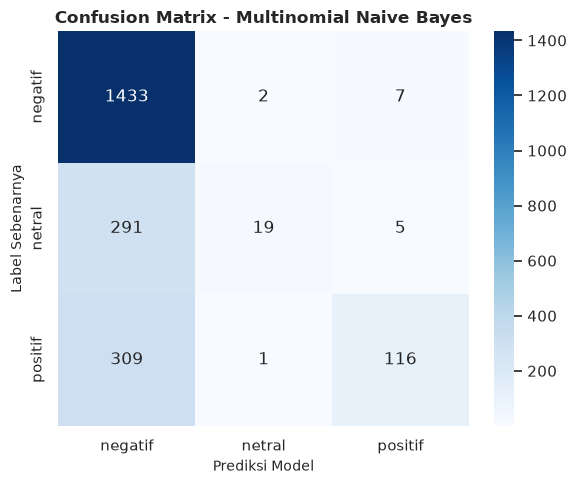

In [65]:
# Membuat Confusion Matrix
labels_order = ['negatif', 'netral', 'positif']
cm_nb = confusion_matrix(y_test, y_pred_test_nb, labels=labels_order)

# Plotting Heatmap
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_nb, 
    annot=True, 
    fmt='d', 
    cmap='Blues',
    xticklabels=labels_order,
    yticklabels=labels_order
)
plt.title('Confusion Matrix - Multinomial Naive Bayes', fontsize=12, fontweight='bold')
plt.xlabel('Prediksi Model', fontsize=10)
plt.ylabel('Label Sebenarnya', fontsize=10)
plt.tight_layout()
plt.show()

# 7. Pemodelan - Skema 2: Advanced ML (Random Forest Classifier + Hyperparameter Tuning)
Skema kedua menerapkan algoritma ensemble **Random Forest Classifier** berbasis TF-IDF. Untuk mengatasi kelemahan Naive Bayes yang bias terhadap kelas mayoritas, model ini dikonfigurasi dengan:
1. **Penyeimbang Kelas (`class_weight='balanced'`)**: Memberikan penalti bobot lebih besar pada kesalahan prediksi kelas minoritas (*netral* dan *positif*).
2. **Hyperparameter Tuning (`GridSearchCV`)**: Melakukan pencarian kombinasi parameter optimal pada jumlah pohon (`n_estimators`), kedalaman maksimum (`max_depth`), dan kriteria pemisahan cabang dengan 3-fold cross validation.

In [66]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

In [67]:
# Definisi grid parameter
param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [20, 40, None],
    'class_weight': ['balanced']
}

# Inisialisasi model dasar Random Forest
rf_base = RandomForestClassifier(random_state=42, n_jobs=-1)

# Pencarian parameter terbaik dengan 3-fold Cross Validation
print("Menjalankan GridSearchCV untuk Random Forest (estimasi 1-2 menit)...")
grid_search_rf = GridSearchCV(
    estimator=rf_base,
    param_grid=param_grid,
    cv=3,
    scoring='f1_weighted',
    n_jobs=-1,
    verbose=1
)

grid_search_rf.fit(X_train_tfidf, y_train)

# Ambil model terbaik hasil tuning
rf_best = grid_search_rf.best_estimator_
print(f"Kombinasi Parameter Terbaik: {grid_search_rf.best_params_}")

# Prediksi data latih dan data uji
y_pred_train_rf = rf_best.predict(X_train_tfidf)
y_pred_test_rf = rf_best.predict(X_test_tfidf)

# Pengukuran akurasi
acc_train_rf = accuracy_score(y_train, y_pred_train_rf)
acc_test_rf = accuracy_score(y_test, y_pred_test_rf)

print("\n--- Hasil Evaluasi Skema 2: Random Forest (Tuned) ---")
print(f"Akurasi Data Latih (Train) : {acc_train_rf * 100:.2f}%")
print(f"Akurasi Data Uji (Test)   : {acc_test_rf * 100:.2f}%")
print("\n--- Laporan Klasifikasi (Data Uji) ---")
print(classification_report(y_test, y_pred_test_rf, digits=4))

Menjalankan GridSearchCV untuk Random Forest (estimasi 1-2 menit)...
Fitting 3 folds for each of 6 candidates, totalling 18 fits
Kombinasi Parameter Terbaik: {'class_weight': 'balanced', 'max_depth': None, 'n_estimators': 200}

--- Hasil Evaluasi Skema 2: Random Forest (Tuned) ---
Akurasi Data Latih (Train) : 98.66%
Akurasi Data Uji (Test)   : 86.07%

--- Laporan Klasifikasi (Data Uji) ---
              precision    recall  f1-score   support

     negatif     0.9162    0.9175    0.9168      1442
      netral     0.7329    0.7841    0.7577       315
     positif     0.7687    0.7254    0.7464       426

    accuracy                         0.8607      2183
   macro avg     0.8059    0.8090    0.8070      2183
weighted avg     0.8610    0.8607    0.8606      2183



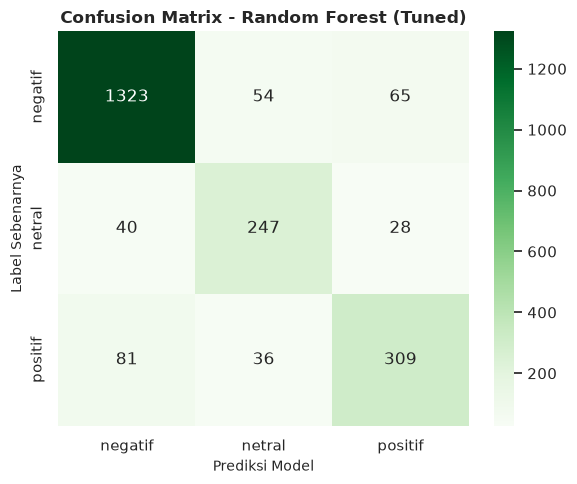

In [68]:
# Membuat Confusion Matrix Random Forest
labels_order = ['negatif', 'netral', 'positif']
cm_rf = confusion_matrix(y_test, y_pred_test_rf, labels=labels_order)

# Plotting Heatmap
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_rf, 
    annot=True, 
    fmt='d', 
    cmap='Greens',
    xticklabels=labels_order,
    yticklabels=labels_order
)
plt.title('Confusion Matrix - Random Forest (Tuned)', fontsize=12, fontweight='bold')
plt.xlabel('Prediksi Model', fontsize=10)
plt.ylabel('Label Sebenarnya', fontsize=10)
plt.tight_layout()
plt.show()

# 8. Pemodelan - Skema 3: Deep Learning (Bidirectional LSTM + Word Embedding)
Skema ketiga menerapkan arsitektur jaringan saraf berulang **Bidirectional Long Short-Term Memory (BiLSTM)** dengan representasi **Word Embedding**.

Kelebihan utama BiLSTM:
- Memproses urutan kata dalam dua arah (maju dan mundur) sehingga konteks kalimat dan kata negasi dipelajari secara utuh.
- Menggunakan lapisan *Embedding* berdimensi padat (*dense vector*) untuk menangkap kedekatan semantik kata.
- Dilengkapi mekanisme penyeimbang bobot kelas (*class weights*) dan *EarlyStopping* untuk memitigasi ketimpangan kelas serta overfitting.

In [69]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.utils import to_categorical
from sklearn.utils.class_weight import compute_class_weight

In [70]:
# Konversi label string ke integer dan one-hot encoding
label_mapping = {'negatif': 0, 'netral': 1, 'positif': 2}
y_train_num = y_train.map(label_mapping).values
y_test_num = y_test.map(label_mapping).values

y_train_cat = to_categorical(y_train_num, num_classes=3)
y_test_cat = to_categorical(y_test_num, num_classes=3)

# Tokenisasi teks dengan Keras Tokenizer
max_vocab_size = 5000
max_sequence_len = 50

tokenizer = Tokenizer(num_words=max_vocab_size, oov_token="<OOV>")
tokenizer.fit_on_texts(X_train)

# Transform teks ke sekuens integer
X_train_seq = tokenizer.texts_to_sequences(X_train)
X_test_seq = tokenizer.texts_to_sequences(X_test)

# Penyeragaman panjang (padding)
X_train_pad = pad_sequences(X_train_seq, maxlen=max_sequence_len, padding='post', truncating='post')
X_test_pad = pad_sequences(X_test_seq, maxlen=max_sequence_len, padding='post', truncating='post')

# Hitung bobot penyeimbang kelas (Class Weights)
class_weights_vals = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train_num),
    y=y_train_num
)
class_weights_dict = dict(enumerate(class_weights_vals))

print("--- Persiapan Data Sekuensial Selesai ---")
print(f"Dimensi X_train_pad : {X_train_pad.shape}")
print(f"Dimensi X_test_pad  : {X_test_pad.shape}")
print(f"Total kosakata unik : {len(tokenizer.word_index)}")
print(f"Pembobotan Kelas    : {class_weights_dict}")

--- Persiapan Data Sekuensial Selesai ---
Dimensi X_train_pad : (8731, 50)
Dimensi X_test_pad  : (2183, 50)
Total kosakata unik : 9408
Pembobotan Kelas    : {0: np.float64(0.5046529102364026), 1: np.float64(2.3097883597883597), 2: np.float64(1.7079420970266042)}


In [71]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, Bidirectional, LSTM, Dense, Dropout, SpatialDropout1D
from tensorflow.keras.optimizers import Adam

In [72]:
# Menentukan parameter arsitektur
embedding_dim = 128

# Membangun model sekuensial
model_bilstm = Sequential([
    Embedding(input_dim=max_vocab_size, output_dim=embedding_dim, input_length=max_sequence_len),
    SpatialDropout1D(0.2),
    Bidirectional(LSTM(64, return_sequences=False, dropout=0.2, recurrent_dropout=0.1)),
    Dense(64, activation='relu'),
    Dropout(0.3),
    Dense(3, activation='softmax')
])

# Kompilasi model
model_bilstm.compile(
    loss='categorical_crossentropy',
    optimizer=Adam(learning_rate=0.001),
    metrics=['accuracy']
)

model_bilstm.summary()

/home/imamriyadi/dev/ai/study/wetv-sentiment-analysis/env/lib/python3.14/site-packages/keras/src/layers/core/embedding.py:123: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d_1             │ ?                      │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [73]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

In [74]:
# Callback untuk menghindari overfitting
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True,
    verbose=1
)

print("Memulai pelatihan model BiLSTM...")
history = model_bilstm.fit(
    X_train_pad, 
    y_train_cat,
    validation_data=(X_test_pad, y_test_cat),
    epochs=15,
    batch_size=64,
    class_weight=class_weights_dict,
    callbacks=[early_stop],
    verbose=1
)

Memulai pelatihan model BiLSTM...
Epoch 1/15
137/137 ━━━━━━━━━━━━━━━━━━━━ 24s 127ms/step - accuracy: 0.6577 - loss: 0.8424 - val_accuracy: 0.8163 - val_loss: 0.4919
Epoch 2/15
137/137 ━━━━━━━━━━━━━━━━━━━━ 16s 113ms/step - accuracy: 0.8684 - loss: 0.4334 - val_accuracy: 0.8717 - val_loss: 0.3601
Epoch 3/15
137/137 ━━━━━━━━━━━━━━━━━━━━ 18s 131ms/step - accuracy: 0.9270 - loss: 0.2631 - val_accuracy: 0.8937 - val_loss: 0.3090
Epoch 4/15
137/137 ━━━━━━━━━━━━━━━━━━━━ 20s 143ms/step - accuracy: 0.9441 - loss: 0.1896 - val_accuracy: 0.8658 - val_loss: 0.3685
Epoch 5/15
137/137 ━━━━━━━━━━━━━━━━━━━━ 16s 113ms/step - accuracy: 0.9584 - loss: 0.1484 - val_accuracy: 0.8809 - val_loss: 0.3660
Epoch 6/15
137/137 ━━━━━━━━━━━━━━━━━━━━ 14s 103ms/step - accuracy: 0.9609 - loss: 0.1298 - val_accuracy: 0.8887 - val_loss: 0.3270
Epoch 6: early stopping
Restoring model weights from the end of the best epoch: 3.


In [75]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

69/69 ━━━━━━━━━━━━━━━━━━━━ 2s 28ms/step

--- Hasil Evaluasi Skema 3: BiLSTM ---
Akurasi Data Latih (Train) : 95.83%
Akurasi Data Uji (Test)   : 89.37%

--- Laporan Klasifikasi (Data Uji) ---
              precision    recall  f1-score   support

     negatif     0.9620    0.9307    0.9461      1442
      netral     0.6829    0.8000    0.7368       315
     positif     0.8520    0.8380    0.8450       426

    accuracy                         0.8937      2183
   macro avg     0.8323    0.8562    0.8426      2183
weighted avg     0.9003    0.8937    0.8961      2183



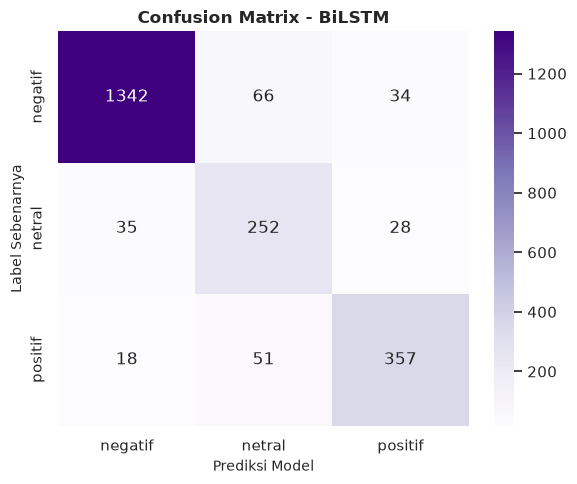

In [76]:
# Prediksi pada data uji
y_pred_probs = model_bilstm.predict(X_test_pad)
y_pred_classes = np.argmax(y_pred_probs, axis=1)

# Evaluasi akurasi
loss_test, acc_test_bilstm = model_bilstm.evaluate(X_test_pad, y_test_cat, verbose=0)
loss_train, acc_train_bilstm = model_bilstm.evaluate(X_train_pad, y_train_cat, verbose=0)

print("\n--- Hasil Evaluasi Skema 3: BiLSTM ---")
print(f"Akurasi Data Latih (Train) : {acc_train_bilstm * 100:.2f}%")
print(f"Akurasi Data Uji (Test)   : {acc_test_bilstm * 100:.2f}%")

# Laporan klasifikasi
target_names = ['negatif', 'netral', 'positif']
print("\n--- Laporan Klasifikasi (Data Uji) ---")
print(classification_report(y_test_num, y_pred_classes, target_names=target_names, digits=4))

# Visualisasi Confusion Matrix
cm_bilstm = confusion_matrix(y_test_num, y_pred_classes)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_bilstm, 
    annot=True, 
    fmt='d', 
    cmap='Purples',
    xticklabels=target_names,
    yticklabels=target_names
)
plt.title('Confusion Matrix - BiLSTM', fontsize=12, fontweight='bold')
plt.xlabel('Prediksi Model', fontsize=10)
plt.ylabel('Label Sebenarnya', fontsize=10)
plt.tight_layout()
plt.show()

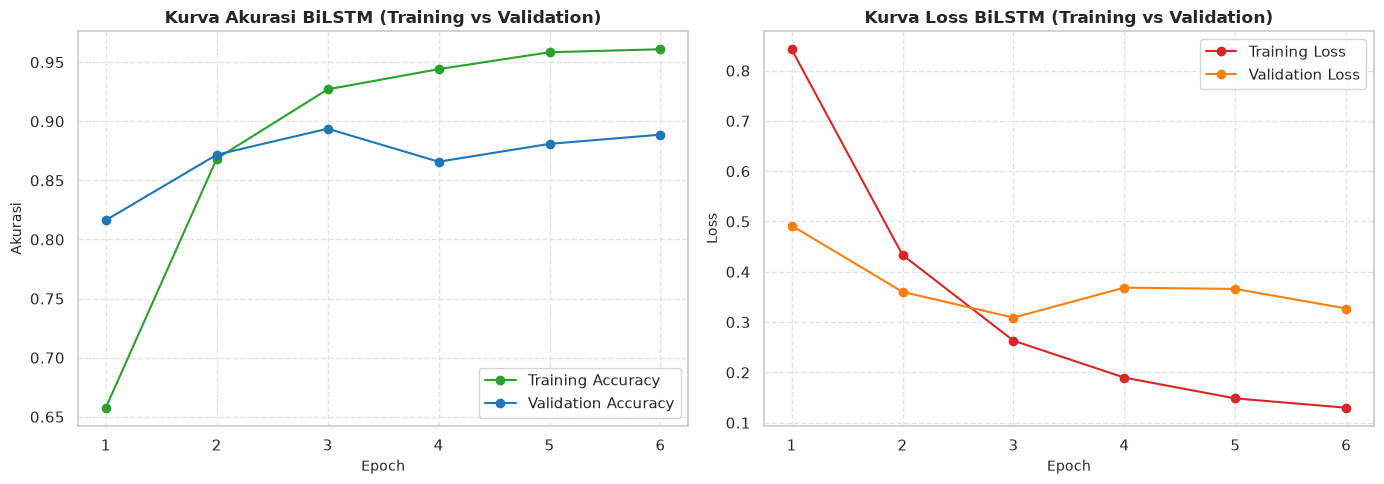

In [77]:
# Mengambil riwayat loss dan akurasi dari proses pelatihan
epochs_range = range(1, len(history.history['loss']) + 1)

plt.figure(figsize=(14, 5))

# Subplot 1: Akurasi (Train vs Validation)
plt.subplot(1, 2, 1)
plt.plot(epochs_range, history.history['accuracy'], marker='o', label='Training Accuracy', color='#2ca02c')
plt.plot(epochs_range, history.history['val_accuracy'], marker='o', label='Validation Accuracy', color='#1f77b4')
plt.title('Kurva Akurasi BiLSTM (Training vs Validation)', fontsize=12, fontweight='bold')
plt.xlabel('Epoch', fontsize=10)
plt.ylabel('Akurasi', fontsize=10)
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.5)

# Subplot 2: Loss (Train vs Validation)
plt.subplot(1, 2, 2)
plt.plot(epochs_range, history.history['loss'], marker='o', label='Training Loss', color='#d62728')
plt.plot(epochs_range, history.history['val_loss'], marker='o', label='Validation Loss', color='#ff7f0e')
plt.title('Kurva Loss BiLSTM (Training vs Validation)', fontsize=12, fontweight='bold')
plt.xlabel('Epoch', fontsize=10)
plt.ylabel('Loss', fontsize=10)
plt.legend(loc='upper right')
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# 9. Evaluasi & Komparasi Kinerja Ketiga Skema Pemodelan
Pada tahap ini, hasil evaluasi dari seluruh skema dirangkum dan dibandingkan secara objektif menggunakan metrik:
1. **Akurasi Data Latih vs Uji** (Generalisasi model)
2. **Macro F1-Score** (Keadilan performa antar kelas tanpa memandang jumlah sampel)
3. **Weighted F1-Score** (Kinerja keseluruhan berbobot proporsi kelas)

In [78]:
from sklearn.metrics import precision_recall_fscore_support

=== RINGKASAN KOMPARASI MODEL ===


,Model,Train Acc (%),Test Acc (%),Macro F1,Weighted F1
0,Multinomial Naive Bayes,75.5813,71.8278,0.4521,0.6428
1,Random Forest (Tuned),98.6599,86.0742,0.8070,0.8606
2,BiLSTM,95.8309,89.3724,0.8426,0.8961


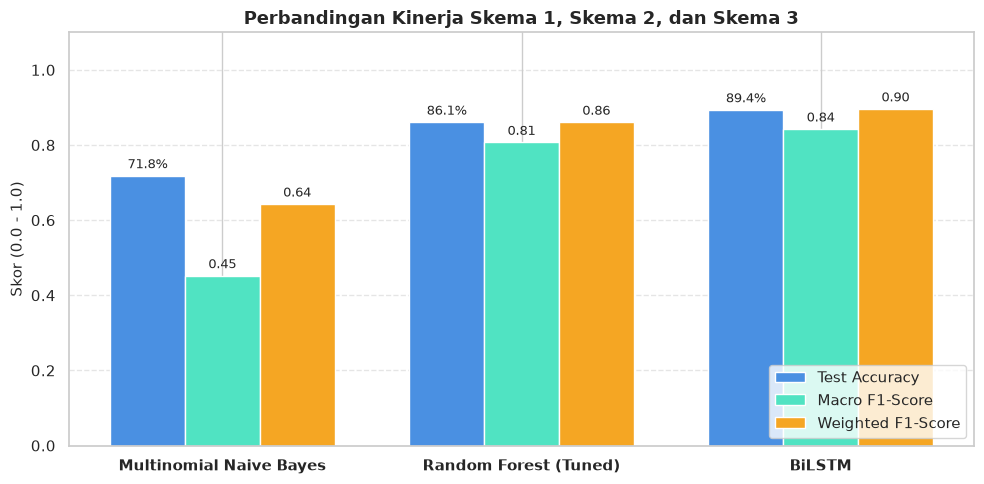

In [79]:
# Menghitung metrik macro & weighted untuk ketiga model
# Skema 1: Multinomial NB
p_nb, r_nb, f1_nb_macro, _ = precision_recall_fscore_support(y_test, y_pred_test_nb, average='macro')
_, _, f1_nb_weighted, _ = precision_recall_fscore_support(y_test, y_pred_test_nb, average='weighted')

# Skema 2: Random Forest
p_rf, r_rf, f1_rf_macro, _ = precision_recall_fscore_support(y_test, y_pred_test_rf, average='macro')
_, _, f1_rf_weighted, _ = precision_recall_fscore_support(y_test, y_pred_test_rf, average='weighted')

# Skema 3: BiLSTM
p_lstm, r_lstm, f1_lstm_macro, _ = precision_recall_fscore_support(y_test_num, y_pred_classes, average='macro')
_, _, f1_lstm_weighted, _ = precision_recall_fscore_support(y_test_num, y_pred_classes, average='weighted')

# Membuat DataFrame Komparasi
summary_df = pd.DataFrame({
    'Model': ['Multinomial Naive Bayes', 'Random Forest (Tuned)', 'BiLSTM'],
    'Train Acc (%)': [acc_train_nb * 100, acc_train_rf * 100, acc_train_bilstm * 100],
    'Test Acc (%)': [acc_test_nb * 100, acc_test_rf * 100, acc_test_bilstm * 100],
    'Macro F1': [f1_nb_macro, f1_rf_macro, f1_lstm_macro],
    'Weighted F1': [f1_nb_weighted, f1_rf_weighted, f1_lstm_weighted]
})

print("=== RINGKASAN KOMPARASI MODEL ===")
display(summary_df.round(4))

# Visualisasi Barchart Komparasi
plt.figure(figsize=(10, 5))
x_axis = np.arange(len(summary_df['Model']))
bar_width = 0.25

plt.bar(x_axis - bar_width, summary_df['Test Acc (%)'] / 100, width=bar_width, label='Test Accuracy', color='#4a90e2')
plt.bar(x_axis, summary_df['Macro F1'], width=bar_width, label='Macro F1-Score', color='#50e3c2')
plt.bar(x_axis + bar_width, summary_df['Weighted F1'], width=bar_width, label='Weighted F1-Score', color='#f5a623')

plt.xticks(x_axis, summary_df['Model'], fontweight='bold', fontsize=11)
plt.ylabel('Skor (0.0 - 1.0)', fontsize=11)
plt.title('Perbandingan Kinerja Skema 1, Skema 2, dan Skema 3', fontsize=13, fontweight='bold')
plt.ylim(0, 1.1)
plt.legend(loc='lower right')
plt.grid(axis='y', linestyle='--', alpha=0.5)

# Menambahkan label nilai di atas bar
for i in x_axis:
    plt.text(i - bar_width, (summary_df['Test Acc (%)'][i] / 100) + 0.02, f"{(summary_df['Test Acc (%)'][i]):.1f}%", ha='center', fontsize=9)
    plt.text(i, summary_df['Macro F1'][i] + 0.02, f"{summary_df['Macro F1'][i]:.2f}", ha='center', fontsize=9)
    plt.text(i + bar_width, summary_df['Weighted F1'][i] + 0.02, f"{summary_df['Weighted F1'][i]:.2f}", ha='center', fontsize=9)

plt.tight_layout()
plt.show()

# 10. Pengujian Inferensi Data Baru
Fungsi `inferensi_model_terbaik` berikut menerima teks ulasan mentah dari pengguna, memprosesnya melalui seluruh pipeline preprocessing teks yang telah dibangun, lalu mengklasifikasikannya menggunakan model terbaik yaitu **BiLSTM**.

In [80]:
def inferensi_model_terbaik():
    print("=" * 60)
    print(" SISTEM INFERENSI SENTIMEN ULASAN WETV (MODEL TERBAIK: BiLSTM)")
    print("=" * 60)
    
    label_map = {0: 'NEGATIF', 1: 'NETRAL', 2: 'POSITIF'}
    
    user_input = input("Masukkan ulasan WeTV yang ingin diuji: ")
    
    if not user_input.strip():
        print("Ulasan kosong. Silakan jalankan ulang cell dan masukkan teks.")
        return
        
    # Eksekusi pipeline prapemrosesan sesuai fungsi lama
    t_clean = clean_text(user_input)
    t_case = case_fold(t_clean)
    t_norm = normalize_slang(t_case)
    t_token = tokenize(t_norm)
    t_stop = filter_stopwords(t_token)
    processed_text = tokens_to_sentence(t_stop)
    
    # Transformasi sequence & padding Keras
    seq = tokenizer.texts_to_sequences([processed_text])
    padded = pad_sequences(seq, maxlen=max_sequence_len, padding='post', truncating='post')
    
    # Prediksi kelas dan probabilitas
    pred_probs = model_bilstm.predict(padded, verbose=0)[0]
    pred_idx = np.argmax(pred_probs)
    pred_label = label_map[pred_idx]
    confidence = pred_probs[pred_idx] * 100
    
    print("\n--- Hasil Analisis Sentimen ---")
    print(f"Teks Asli        : \"{user_input}\"")
    print(f"Teks Bersih      : \"{processed_text}\"")
    print(f"Prediksi Sentimen: {pred_label} (Tingkat Keyakinan: {confidence:.2f}%)")
    print("-" * 60)
    print("Rincian Probabilitas:")
    for idx, prob in enumerate(pred_probs):
        print(f"- {label_map[idx]:<8} : {prob * 100:.2f}%")
    print("=" * 60)

# Jalankan fungsi inferensi interaktif
inferensi_model_terbaik()

 SISTEM INFERENSI SENTIMEN ULASAN WETV (MODEL TERBAIK: BiLSTM)

--- Hasil Analisis Sentimen ---
Teks Asli        : "saya sudah bayar, tapi kenapa masih ada iklan. jelek kalau begini."
Teks Bersih      : "bayar iklan jelek"
Prediksi Sentimen: NEGATIF (Tingkat Keyakinan: 99.91%)
------------------------------------------------------------
Rincian Probabilitas:
- NEGATIF  : 99.91%
- NETRAL   : 0.08%
- POSITIF  : 0.00%
